# Módulo 5 — Práctica Día 9: diagrama de Taylor y valor añadido

Ejercicios 1–3 de la práctica del **Día 9** (ver [`README.md`](../README.md)).
La automatización multi-estación (Ejercicio 4) se hace en
[`04_entregable_automatizacion.ipynb`](04_entregable_automatizacion.ipynb).
Todos los datos son reales: WRF y ERA5-Land del Módulo 4/5, estaciones
reales dentro del dominio del WRF (`data/ogimet/coords_area_wrf.json`),
observación horaria decodificada de mensajes SYNOP.

> **📍 Nota para curso con 2 grupos:** Salto es la estación de referencia compartida (Ejercicios 1-3). En la "práctica dirigida" (celda con `estacion_practica`, más abajo), cada grupo usa una estación de su propia subregión en vez de elegir libremente:
> - **Grupo 1 (Norte):** `estacion_practica = "Iguazu"` o `"Resistencia"`.
> - **Grupo 2 (Sur):** `estacion_practica = "Rosario"`, `"Ezeiza"` o `"Carrasco"`.

In [1]:
import sys
sys.path.insert(0, ".")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from metricas import calcular_mae, calcular_rmse, calcular_bias, calcular_r, calcular_kge

coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))

# wrfout_muestra.nc: dia completo (24 horas UTC), solo variables de superficie.
# No trae SINALPHA/COSALPHA -- no hacen falta: el Modulo 4 establecio que en
# este dominio (Mercator) U10/V10 crudos YA son earth-relative. Tampoco hace
# falta xwrf: XLAT/XLONG/XTIME ya vienen listos para usar.
ds_wrf = xr.open_dataset("../../../data/grid_muestra/wrfout_muestra.nc")
era5 = xr.open_dataset("../../../data/era_muestra/era5_land_20241213.nc")
tiempos = pd.to_datetime(ds_wrf["XTIME"].values)

def punto_mas_cercano(ds, lat, lon):
    dist2 = (ds["XLAT"] - lat) ** 2 + (ds["XLONG"] - lon) ** 2
    return np.unravel_index(np.argmin(dist2.values), dist2.shape)

def cargar_estacion(nombre):
    """obs real (SYNOP), WRF real y ERA5-Land real en el punto más cercano a `nombre`,
    en las 24 horas del día que tiene el wrfout de muestra."""
    c = coords[nombre]
    iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])
    obs_horaria = pd.read_csv(f"../../../data/obs/{nombre}_2024_12_13_horario.csv",
                               parse_dates=["tiempo"]).set_index("tiempo")
    obs = obs_horaria.reindex(tiempos)["temp_C"]
    wrf = pd.Series((ds_wrf["T2"].isel(south_north=iy, west_east=ix) - 273.15).values, index=tiempos)
    modelo_global = pd.Series(
        era5["t2m"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values - 273.15,
        index=tiempos)
    return obs, wrf, modelo_global

obs, wrf, modelo_global = cargar_estacion("Salto")
print("Datos cargados (Salto, 24 h). r(WRF, obs) =", round(calcular_r(wrf.values, obs.values), 3))

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Datos cargados (Salto, 24 h). r(WRF, obs) = 0.888


## Ejercicio 1 (opcional, si sobra tiempo) — Un punto del diagrama de Taylor a mano

> Puedes ejecutar esta celda sin modificarla y pasar al Ejercicio 2: solo
> confirma que la fórmula del diagrama coincide con el cálculo directo.

In [2]:
sigma_s = float(np.std(wrf.values))
sigma_o = float(np.std(obs.values))
_, comp = calcular_kge(wrf.values, obs.values)
r = comp["r"]

rmse_centrado_ley_cosenos = np.sqrt(sigma_s**2 + sigma_o**2 - 2 * sigma_s * sigma_o * r)

anomalia_s = wrf.values - wrf.values.mean()
anomalia_o = obs.values - obs.values.mean()
rmse_centrado_directo = calcular_rmse(anomalia_s, anomalia_o)

print(f"sigma_sim={sigma_s:.3f}  sigma_obs={sigma_o:.3f}  r={r:.3f}")
print(f"RMSE centrado (ley de cosenos): {rmse_centrado_ley_cosenos:.4f}")
print(f"RMSE centrado (directo):        {rmse_centrado_directo:.4f}")
print(f"¿Coinciden? -> {np.isclose(rmse_centrado_ley_cosenos, rmse_centrado_directo)}")

sigma_sim=3.326  sigma_obs=2.100  r=0.888
RMSE centrado (ley de cosenos): 1.7502
RMSE centrado (directo):        1.7502
¿Coinciden? -> True


## Ejercicio 2 — Diagrama de Taylor con SkillMetrics (60 min)

Un diagrama de Taylor compara **una referencia** (la observación) contra
**uno o más modelos** en el mismo punto. Acá usamos **Salto** como
estación de referencia y comparamos sus dos "modelos" reales — WRF y
ERA5-Land — dando **3 puntos**: 1 de referencia + 2 de modelos. Se usa el
paquete [`SkillMetrics`](https://github.com/PeterRochford/SkillMetrics),
que implementa exactamente la fórmula de la ley de cosenos del Ejercicio 1
(`sm.taylor_statistics` calcula σ, RMSD centrado y r; `sm.taylor_diagram`
los ubica geométricamente).

sigma_obs (SkillMetrics) = 2.100  |  sigma_obs (Ejercicio 1) = 2.100
RMSD centrado WRF (SkillMetrics) = 1.7502  |  (Ejercicio 1) = 1.7502


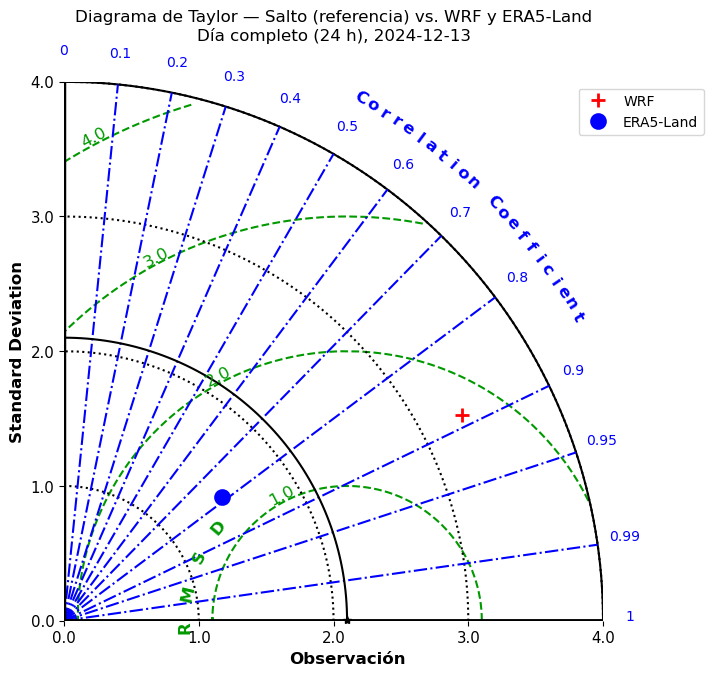

In [3]:
import skill_metrics as sm

st_wrf = sm.taylor_statistics(wrf.values, obs.values)
st_era5 = sm.taylor_statistics(modelo_global.values, obs.values)

# indice 0 = referencia (observacion); SkillMetrics recalcula sigma/RMSD/r
# el resultado debe coincidir con el Ejercicio 1 (misma formula, mismos datos)
sdev = np.array([st_wrf["sdev"][0], st_wrf["sdev"][1], st_era5["sdev"][1]])
crmsd = np.array([st_wrf["crmsd"][0], st_wrf["crmsd"][1], st_era5["crmsd"][1]])
ccoef = np.array([st_wrf["ccoef"][0], st_wrf["ccoef"][1], st_era5["ccoef"][1]])

print(f"sigma_obs (SkillMetrics) = {sdev[0]:.3f}  |  sigma_obs (Ejercicio 1) = {sigma_o:.3f}")
print(f"RMSD centrado WRF (SkillMetrics) = {crmsd[1]:.4f}  |  (Ejercicio 1) = {rmse_centrado_directo:.4f}")

etiquetas = ["Observación (Salto)", "WRF", "ERA5-Land"]
plt.figure(figsize=(7, 7))
sm.taylor_diagram(sdev, crmsd, ccoef,
                   markerLabel=etiquetas, markerLegend="on",
                   styleOBS="-", colOBS="k", markerobs="*", titleOBS="Observación")
plt.title("Diagrama de Taylor — Salto (referencia) vs. WRF y ERA5-Land\nDía completo (24 h), 2024-12-13", pad=30)
plt.savefig("diagrama_taylor.png", dpi=100, bbox_inches="tight")
plt.show()

### Práctica dirigida — repetir con otra estación (20 min)

Las 5 estaciones restantes (`Ezeiza`, `Rosario`, `Resistencia`, `Iguazu`,
`Carrasco`) no se usaron arriba — quedan para que cada participante/grupo
repita el mismo diagrama con la estación que le toque, usando
`cargar_estacion()` ya definida al inicio del notebook.

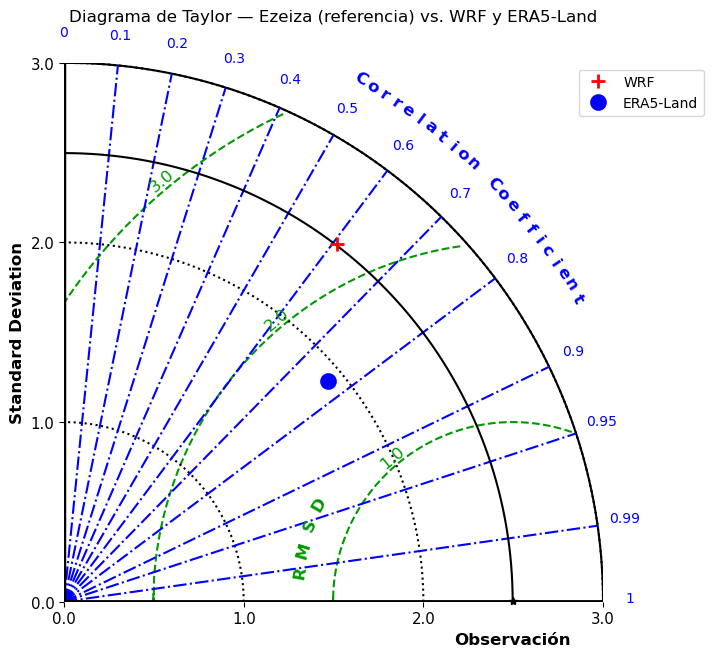

¿En Ezeiza, cuál modelo cae más cerca de la referencia? Compárenlo con el resultado de Salto.


In [4]:
estacion_practica = "Ezeiza"  # <- cambiar por la estación asignada

obs_p, wrf_p, modelo_global_p = cargar_estacion(estacion_practica)

st_wrf_p = sm.taylor_statistics(wrf_p.values, obs_p.values)
st_era5_p = sm.taylor_statistics(modelo_global_p.values, obs_p.values)

sdev_p = np.array([st_wrf_p["sdev"][0], st_wrf_p["sdev"][1], st_era5_p["sdev"][1]])
crmsd_p = np.array([st_wrf_p["crmsd"][0], st_wrf_p["crmsd"][1], st_era5_p["crmsd"][1]])
ccoef_p = np.array([st_wrf_p["ccoef"][0], st_wrf_p["ccoef"][1], st_era5_p["ccoef"][1]])

plt.figure(figsize=(7, 7))
sm.taylor_diagram(sdev_p, crmsd_p, ccoef_p,
                   markerLabel=[f"Observación ({estacion_practica})", "WRF", "ERA5-Land"],
                   markerLegend="on", styleOBS="-", colOBS="k", markerobs="*", titleOBS="Observación")
plt.title(f"Diagrama de Taylor — {estacion_practica} (referencia) vs. WRF y ERA5-Land", pad=30)
plt.show()

print(f"¿En {estacion_practica}, cuál modelo cae más cerca de la referencia? Compárenlo con el resultado de Salto.")

## Ejercicio 3 — Cálculo de added value (50 min)

**Definición general (la que se usa en meteorología, no solo en este
curso):** el valor añadido de una simulación regional de alta resolución
(el WRF) se cuantifica comparando, contra un mismo **dato observado real
(el dato de referencia)**, dos fuentes distintas de estimación en el mismo
punto:

1. El **modelo global** (ERA5 o GFS) **interpolado** a la ubicación exacta
   de la observación.
2. La **salida del WRF interpolada** a esa misma ubicación.

Si las métricas del WRF son mejores que las del modelo global, hay
evidencia de que la resolución fina y la física adicional del WRF capturan
algo que el dato global no resuelve. Esto se conecta con la advertencia de
circularidad del Día 8: aquí el modelo global se usa explícitamente como el
otro extremo de la comparación ("¿le gana el WRF?"), no como si fuera la
observación de verdad.

In [5]:
# obs, wrf y modelo_global (ERA5-Land) ya se cargaron arriba para Salto -- son
# el mismo dato real usado en el diagrama de Taylor del Ejercicio 2.

filas = []
for nombre_fuente, serie in [("WRF", wrf), ("Modelo global (ERA5-Land)", modelo_global)]:
    kge_i, comp_i = calcular_kge(serie.values, obs.values)
    filas.append({
        "fuente": nombre_fuente,
        "RMSE": calcular_rmse(serie.values, obs.values),
        "MAE": calcular_mae(serie.values, obs.values),
        "bias": calcular_bias(serie.values, obs.values),
        "r": comp_i["r"],
        "KGE": kge_i,
    })

tabla_added_value = pd.DataFrame(filas).set_index("fuente").round(3)
tabla_added_value

,RMSE,MAE,bias,r,KGE
fuente,,,,,
WRF,1.997,1.540,0.962,0.888,0.405
Modelo global (ERA5-Land),1.466,1.055,0.664,0.787,0.639


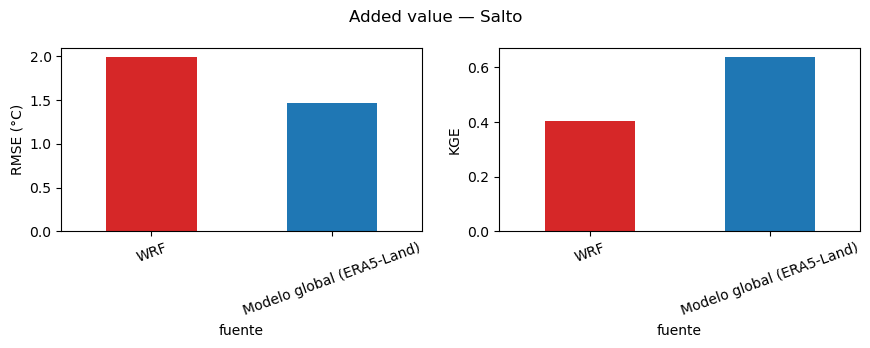

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
tabla_added_value["RMSE"].plot(kind="bar", ax=axes[0], color=["tab:red", "tab:blue"])
axes[0].set_ylabel("RMSE (°C)")
axes[0].tick_params(axis="x", rotation=20)
tabla_added_value["KGE"].plot(kind="bar", ax=axes[1], color=["tab:red", "tab:blue"])
axes[1].set_ylabel("KGE")
axes[1].tick_params(axis="x", rotation=20)
fig.suptitle("Added value — Salto")
fig.tight_layout()
plt.show()

In [7]:
mejora_rmse = tabla_added_value.loc["Modelo global (ERA5-Land)", "RMSE"] - tabla_added_value.loc["WRF", "RMSE"]
mejora_kge = tabla_added_value.loc["WRF", "KGE"] - tabla_added_value.loc["Modelo global (ERA5-Land)", "KGE"]

print(f"Reducción de RMSE del WRF frente al modelo global: {mejora_rmse:.3f} °C")
print(f"Mejora de KGE del WRF frente al modelo global:     {mejora_kge:.3f}")
print(f"¿Hay evidencia de valor añadido? -> {mejora_rmse > 0 and mejora_kge > 0}")
print()
print("En Salto, con el día completo (n=24) y datos reales, la respuesta es NO: ni el")
print("RMSE ni el KGE del WRF mejoran frente a ERA5-Land en este punto. Es un resultado")
print("legítimo, no un error -- ver la extensión completa (todas las estaciones a la vez)")
print("en el notebook entregable para una lectura menos sensible a una sola estación.")

Reducción de RMSE del WRF frente al modelo global: -0.531 °C
Mejora de KGE del WRF frente al modelo global:     -0.234
¿Hay evidencia de valor añadido? -> False

En Salto, con el día completo (n=24) y datos reales, la respuesta es NO: ni el
RMSE ni el KGE del WRF mejoran frente a ERA5-Land en este punto. Es un resultado
legítimo, no un error -- ver la extensión completa (todas las estaciones a la vez)
en el notebook entregable para una lectura menos sensible a una sola estación.


## Cierre

Entregable parcial: este notebook + `diagrama_taylor.png`. Continuar con
[`04_entregable_automatizacion.ipynb`](04_entregable_automatizacion.ipynb).